# 02 - Spatial Preparation

This notebook documents the spatial preparation of the London PM2.5 project.

The workflow is: 20 m PM2.5 grid -> 500 m modelling grid -> traffic aggregation -> green-cover aggregation -> final spatial modelling dataset.

In [7]:
from pathlib import Path
import sys

import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import CRS_EPSG, PROCESSED_DIR

GRID_FILE = PROCESSED_DIR / "london_500m_grid.gpkg"
PM25_FILE = PROCESSED_DIR / "pm25_500m.parquet"
TRAFFIC_FILE = PROCESSED_DIR / "traffic_500m.parquet"
GREEN_FILE = PROCESSED_DIR / "green_cover_500m.parquet"

grid = gpd.read_file(GRID_FILE, layer="london_500m_grid")
pm25 = pd.read_parquet(PM25_FILE)
traffic = pd.read_parquet(TRAFFIC_FILE)
green = pd.read_parquet(GREEN_FILE)

print("Grid cells:", len(grid), "CRS:", grid.crs)
print("PM2.5 rows:", len(pm25))
print("Traffic rows:", len(traffic))
print("Green-cover rows:", len(green))

Grid cells: 6672 CRS: EPSG:27700
PM2.5 rows: 6670
Traffic rows: 6672
Green-cover rows: 6672


In [2]:
print("PM2.5 fields:", pm25.columns.tolist())
print("Traffic fields:", traffic.columns.tolist())
print("Green-cover fields:", green.columns.tolist())

master = (
    pm25
    .merge(traffic, on="grid_id", how="left", validate="one_to_one")
    .merge(green[["grid_id", "green_area_m2", "green_cover_pct"]], on="grid_id", how="left", validate="one_to_one")
    .merge(grid[["grid_id", "centroid_x", "centroid_y", "area_m2"]], on="grid_id", how="left", validate="one_to_one")
)
print("Merged rows:", len(master))
print("Merged columns:", len(master.columns))
display(master.head())

PM2.5 fields: ['grid_id', 'grid_x', 'grid_y', 'pm25_mean', 'pm25_median', 'pm25_min', 'pm25_max', 'pm25_std', 'n_pm25_cells', 'area_m2']
Traffic fields: ['grid_id', 'major_road_length_m', 'major_vehicle_m_per_day', 'major_hgv_vehicle_m_per_day', 'major_mean_aadf', 'major_hgv_mean_aadf', 'minor_vkm_total', 'minor_hgv_vkm']
Green-cover fields: ['grid_id', 'area_m2', 'green_area_m2', 'green_cover_pct']
Merged rows: 6670
Merged columns: 22


,grid_id,grid_x,grid_y,pm25_mean,pm25_median,pm25_min,pm25_max,pm25_std,n_pm25_cells,area_m2_x,...,major_hgv_vehicle_m_per_day,major_mean_aadf,major_hgv_mean_aadf,minor_vkm_total,minor_hgv_vkm,green_area_m2,green_cover_pct,centroid_x,centroid_y,area_m2_y
0,G00001,503500,175000,8.883902,8.468357,7.899553,12.644440,0.990951,623,250000.0,...,5.406015e+06,24349.425376,2454.741385,2.011335e+05,9712.531133,41835.862001,16.734345,503750.0,175250.0,250000.0
1,G00002,503500,175500,9.139251,8.874873,8.187171,12.014450,0.903982,419,250000.0,...,8.774429e+06,37358.573847,3670.796720,1.783822e+05,8556.092427,59242.470993,23.696988,503750.0,175750.0,250000.0
2,G00003,503500,176000,9.331372,8.749233,8.238686,12.012400,1.164536,230,250000.0,...,8.051956e+06,49492.199098,4867.351405,1.218431e+07,521618.113937,5744.725656,2.297890,503750.0,176250.0,250000.0
3,G00004,503500,176500,8.717595,8.520021,8.223557,11.797150,0.589266,104,250000.0,...,1.139705e+06,91104.000000,9539.000000,2.305859e+06,101952.088150,1068.805097,0.427522,503750.0,176750.0,250000.0
4,G00005,503500,189500,7.481036,7.434715,7.380218,8.633005,0.156413,625,250000.0,...,0.000000e+00,0.000000,0.000000,3.446926e+05,16838.967983,6227.529328,2.491012,503750.0,189750.0,250000.0


In [5]:
print("Missing values:")
display(master.isna().sum().sort_values(ascending=False))

print("PM2.5 aggregation coverage:")
display(pm25[["pm25_mean", "pm25_min", "pm25_max", "n_pm25_cells"]].describe().T)
print("Green-cover coverage:")
display(green[["green_area_m2", "green_cover_pct"]].describe().T)
print("Traffic predictors:")
display(traffic[["major_road_length_m", "major_mean_aadf", "major_hgv_mean_aadf", "minor_vkm_total", "minor_hgv_vkm"]].describe().T)

Missing values:


grid_id                        0
grid_x                         0
grid_y                         0
pm25_mean                      0
pm25_median                    0
pm25_min                       0
pm25_max                       0
pm25_std                       0
n_pm25_cells                   0
area_m2_x                      0
major_road_length_m            0
major_vehicle_m_per_day        0
major_hgv_vehicle_m_per_day    0
major_mean_aadf                0
major_hgv_mean_aadf            0
minor_vkm_total                0
minor_hgv_vkm                  0
green_area_m2                  0
green_cover_pct                0
centroid_x                     0
centroid_y                     0
area_m2_y                      0
dtype: int64

PM2.5 aggregation coverage:


,count,mean,std,min,25%,50%,75%,max
pm25_mean,6670.0,8.773117,0.728961,7.033696,8.255383,8.738196,9.248711,11.674392
pm25_min,6670.0,8.528964,0.628820,7.010097,8.077649,8.514981,8.947819,11.183250
pm25_max,6670.0,11.166249,3.077700,7.037420,9.160947,10.788805,12.382333,123.206400
n_pm25_cells,6670.0,622.349025,32.389724,25.000000,625.000000,625.000000,625.000000,625.000000


Green-cover coverage:


,count,mean,std,min,25%,50%,75%,max
green_area_m2,6672.0,119988.494104,66186.355358,0.0,68595.669857,106770.846560,168577.254770,250000.0
green_cover_pct,6672.0,47.995398,26.474542,0.0,27.438268,42.708339,67.430902,100.0


Traffic predictors:


,count,mean,std,min,25%,50%,75%,max
major_road_length_m,6672.0,715.756946,671.756086,0.0,127.446020,582.421952,1.058676e+03,5.364805e+03
major_mean_aadf,6672.0,10405.484734,10267.489378,0.0,2432.488633,9046.979755,1.481632e+04,9.143453e+04
major_hgv_mean_aadf,6672.0,452.210255,1142.582938,0.0,5.153039,162.348388,4.820729e+02,1.401067e+04
minor_vkm_total,6672.0,965685.590376,995947.518969,0.0,357721.581854,775986.733968,1.357797e+06,2.626114e+07
minor_hgv_vkm,6672.0,36437.015359,40012.097300,0.0,12366.872811,28724.685031,5.244243e+04,9.975388e+05


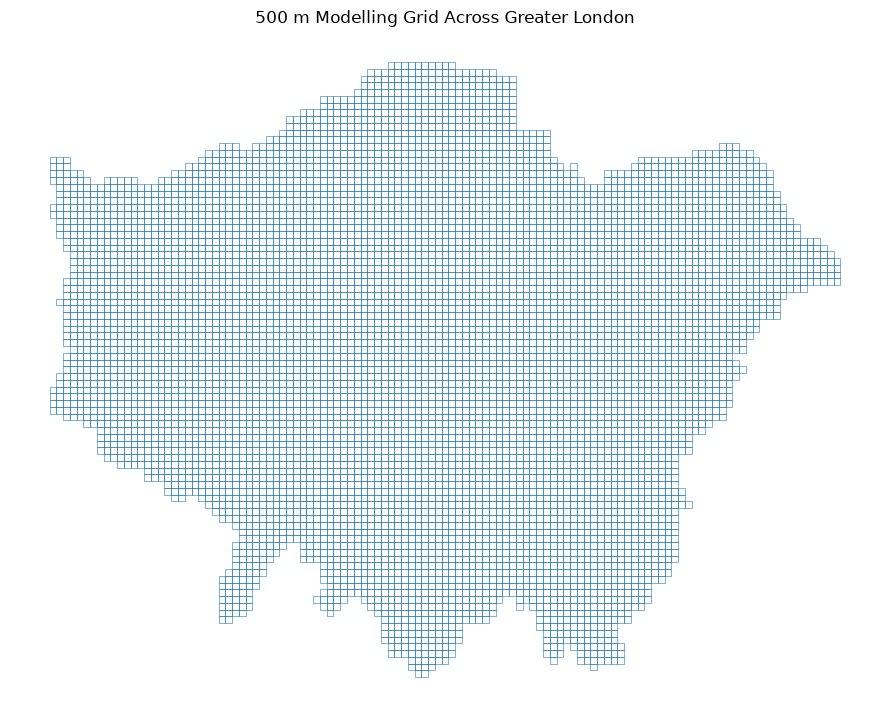

Final usable PM2.5 cells: 6670
Final grid cells: 6672


In [6]:
fig, ax = plt.subplots(figsize=(9, 9))
grid.boundary.plot(ax=ax, linewidth=0.4)
ax.set_title("500 m Modelling Grid Across Greater London")
ax.set_axis_off()
plt.tight_layout()
plt.show()

print("Final usable PM2.5 cells:", pm25["grid_id"].nunique())
print("Final grid cells:", grid["grid_id"].nunique())

## Spatial preparation decisions

PM2.5 values were aggregated from the 20 m grid to the 500 m analytical grid using the mean concentration. Traffic and green-cover data were spatially aligned to the same grid. Green cover is the mapped green-cover area within each cell divided by cell area.